# 05 - So sánh các model đã có (rerun / evaluate / compare)

Notebook này **không** train model mới và **không** tinh chỉnh tham số. Nó chỉ nạp lại các model đã được
notebook 02, 03, 04 lưu trong `models/` ở lần chạy gần nhất, rồi đánh giá chúng bằng **cùng một bộ chỉ số
trên cùng một tập đánh giá** để so sánh công bằng.

| Model | Notebook | Artifact | Ngưỡng |
|---|---|---|---|
| RF baseline (lần 1) | 02 | `random_forest.joblib` | 0.5 (mặc định của `predict`) |
| RF tuned + ngưỡng CV (lần 2) | 03 | `random_forest_v2.joblib` | `best_threshold_` học bằng CV trên train |
| RF tuned + isotonic calibration + ngưỡng FPR<=0.10 (lần 3, cấu hình C_dev) | 04 | `random_forest_v3_calibrated.joblib` | `threshold` chọn trên test-dev |

**Vấn đề về tính so sánh được:** notebook 02 và 03 đánh giá trên **toàn bộ** tập test đã làm sạch
(50.567 dòng), còn notebook 04 chia tập test thành `test-dev` (chọn ngưỡng) và `test-final` (đánh giá
một lần). Vì model lần 3 đã *nhìn thấy* `test-dev` khi chọn ngưỡng, tập đánh giá chung duy nhất mà
**cả ba** model đều chưa dùng cho bất kỳ quyết định nào là `test-final`.

- **Bảng chính** = cả ba model trên `test-final` (so sánh công bằng).
- **Bảng tham chiếu** = số liệu trên toàn bộ tập test, đúng như từng notebook báo cáo; riêng lần 3 bị
  đánh dấu là **lạc quan** vì nửa tập test đã dùng để chọn ngưỡng.

In [1]:
import os

# Tự nhận diện môi trường: Colab (mount Google Drive) hoặc máy local (Google Drive for Desktop)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/5G_IDS_Project'
except ImportError:
    # Notebook nằm trong 5G_IDS_Project/notebooks -> thư mục project là thư mục cha
    BASE = os.path.abspath('..')

print("Thư mục project:", BASE)

Thư mục project: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project


## 1. Nạp dữ liệu và tái tạo tập `test-final`

`test-final` được lấy lại từ file chia tập mà notebook 04 đã lưu (`data/cleaned/test_split_v3.csv`),
không chia lại, để đúng tập mà notebook 04 đã dùng.

In [2]:
import json
import numpy as np
import pandas as pd

cleaned_dir = os.path.join(BASE, 'data', 'cleaned')
models_dir = os.path.join(BASE, 'models')
reports_dir = os.path.join(BASE, 'reports')

target_cols = ['label', 'attack_cat']
categorical_cols = ['proto', 'service', 'state']
removed_cols = ['id', 'ct_state_ttl', 'sttl', 'dttl', 'ct_dst_ltm', 'ct_srv_dst', 'ct_dst_src_ltm', 'ct_srv_ltm',
                'ct_srv_src', 'ct_dst_sport_ltm', 'is_sm_ips_ports', 'ct_ftp_cmd', 'is_ftp_login']

train = pd.read_parquet(os.path.join(cleaned_dir, 'UNSW_NB15_training-set.parquet'))
test = pd.read_parquet(os.path.join(cleaned_dir, 'UNSW_NB15_testing-set.parquet'))


def features(df):
    return df.drop(columns=target_cols).astype({c: str for c in categorical_cols})


# Tập đánh giá chung: test-final (nửa tập test, đúng cách chia của notebook 04)
split = pd.read_csv(os.path.join(cleaned_dir, 'test_split_v3.csv'))
final_idx = split.loc[split['split'] == 'test_final', 'test_index']
test_final = test.loc[final_idx]

eval_sets = {
    'test-final (50% tập test, chung cho cả 3 model)': (features(test_final), test_final['label']),
    'toàn bộ tập test (như notebook 02/03 báo cáo)': (features(test), test['label']),
}

# Kiểm tra: không có cột mục tiêu / cột ô nhiễm trong feature
for name, (X_, y_) in eval_sets.items():
    assert not set(target_cols + removed_cols) & set(X_.columns)

display(pd.DataFrame({
    'n': [len(train), len(test), len(test_final)],
    'Normal (0)': [(train['label'] == 0).sum(), (test['label'] == 0).sum(), (test_final['label'] == 0).sum()],
    'Attack (1)': [(train['label'] == 1).sum(), (test['label'] == 1).sum(), (test_final['label'] == 1).sum()],
    'tỷ lệ Attack': [train['label'].mean(), test['label'].mean(), test_final['label'].mean()],
}, index=['train (đã làm sạch)', 'test (đã làm sạch)', 'test-final']).round(4))

,n,Normal (0),Attack (1),tỷ lệ Attack
train (đã làm sạch),98934,49825,49109,0.4964
test (đã làm sạch),50567,32034,18533,0.3665
test-final,25284,16017,9267,0.3665


## 2. Nạp các model đã lưu và định nghĩa chỉ số dùng chung

Mỗi model giữ **đúng** ngưỡng quyết định mà notebook của nó đã chọn. Không model nào được fit lại ở đây.

In [3]:
import joblib

run1 = joblib.load(os.path.join(models_dir, 'random_forest.joblib'))            # notebook 02
run2 = joblib.load(os.path.join(models_dir, 'random_forest_v2.joblib'))         # notebook 03
run3 = joblib.load(os.path.join(models_dir, 'random_forest_v3_calibrated.joblib'))  # notebook 04

# (tên hiển thị, hàm trả P(Attack), ngưỡng)
models = {
    'RF baseline (NB02)': (lambda X_: run1.predict_proba(X_)[:, 1], 0.5),
    'RF tuned + ngưỡng CV (NB03)': (lambda X_: run2.estimator_.predict_proba(X_)[:, 1], float(run2.best_threshold_)),
    'RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04, C_dev)':
        (lambda X_: run3['model'].predict_proba(X_)[:, 1], float(run3['threshold'])),
}
for name, (_, thr) in models.items():
    print(f'{name}: ngưỡng = {thr:.4f}')

# Tham số RF thực tế của từng model (đọc từ chính estimator đã lưu)
keys = ['n_estimators', 'max_depth', 'max_features', 'min_samples_split', 'min_samples_leaf',
        'max_samples', 'class_weight', 'criterion', 'bootstrap', 'random_state']
rfs = {
    'RF baseline (NB02)': run1.named_steps['rf'],
    'RF tuned + ngưỡng CV (NB03)': run2.estimator_.named_steps['rf'],
    'RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04, C_dev)':
        run3['model'].calibrated_classifiers_[0].estimator.named_steps['rf'],
}
params_table = pd.DataFrame({n: {k: rf.get_params()[k] for k in keys} for n, rf in rfs.items()})
display(params_table)

RF baseline (NB02): ngưỡng = 0.5000
RF tuned + ngưỡng CV (NB03): ngưỡng = 0.5152
RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04, C_dev): ngưỡng = 0.7106


,RF baseline (NB02),RF tuned + ngưỡng CV (NB03),"RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04, C_dev)"
n_estimators,100,300,300
max_depth,None,20,20
max_features,sqrt,0.5,0.5
min_samples_split,2,2,2
min_samples_leaf,1,1,1
max_samples,None,0.7,0.7
class_weight,None,None,None
criterion,gini,gini,gini
bootstrap,True,True,True
random_state,42,42,42


In [4]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, average_precision_score, confusion_matrix)


def evaluate(proba, y_true, threshold):
    # Cùng định nghĩa chỉ số cho mọi model: Attack nếu P(Attack) >= threshold
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'Accuracy': accuracy_score(y_true, pred), 'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred),
            'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
            'FPR': fp / (fp + tn), 'Balanced acc': balanced_accuracy_score(y_true, pred),
            'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
            'Ngưỡng': threshold}


results = {}
for set_name, (X_, y_) in eval_sets.items():
    for name, (proba_fn, thr) in models.items():
        results[(set_name, name)] = evaluate(proba_fn(X_), y_, thr)

all_results = pd.DataFrame(results).T
all_results.index.names = ['Tập đánh giá', 'Model']
print('Đã đánh giá', len(all_results), 'cặp (tập đánh giá, model)')

Đã đánh giá 6 cặp (tập đánh giá, model)


## 3. Bảng so sánh chính - cả ba model trên cùng tập `test-final`

In [5]:
num_cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'FPR', 'Balanced acc', 'ROC-AUC', 'PR-AUC', 'Ngưỡng']
EVAL_MAIN = 'test-final (50% tập test, chung cho cả 3 model)'
EVAL_FULL = 'toàn bộ tập test (như notebook 02/03 báo cáo)'

main = all_results.loc[EVAL_MAIN]
display(main[['Accuracy', 'Precision', 'Recall', 'F1']].astype(float).round(4))
display(main[['TN', 'FP', 'FN', 'TP', 'FPR', 'ROC-AUC', 'PR-AUC', 'Ngưỡng']]
        .style.format({c: '{:.4f}' for c in ['FPR', 'ROC-AUC', 'PR-AUC', 'Ngưỡng']}))

,Accuracy,Precision,Recall,F1
Model,,,,
RF baseline (NB02),0.8156,0.6773,0.9491,0.7905
RF tuned + ngưỡng CV (NB03),0.8287,0.6965,0.9438,0.8015
"RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04, C_dev)",0.8820,0.8251,0.8605,0.8424


,TN,FP,FN,TP,FPR,ROC-AUC,PR-AUC,Ngưỡng
Model,,,,,,,,
RF baseline (NB02),11827.000000,4190.000000,472.000000,8795.000000,0.2616,0.9548,0.9264,0.5000
RF tuned + ngưỡng CV (NB03),12206.000000,3811.000000,521.000000,8746.000000,0.2379,0.9600,0.9420,0.5152
"RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04, C_dev)",14327.000000,1690.000000,1293.000000,7974.000000,0.1055,0.9595,0.9416,0.7106


## 4. Bảng tham chiếu - toàn bộ tập test

⚠️ Dòng của model lần 3 (NB04) ở bảng này **lạc quan**: ngưỡng của nó được chọn trên `test-dev`,
là nửa còn lại của chính tập test này. Dùng bảng ở mục 3 khi so sánh.

In [6]:
full = all_results.loc[EVAL_FULL]
display(full[['Accuracy', 'Precision', 'Recall', 'F1']].astype(float).round(4))

# Đối chiếu với metrics JSON mà notebook 02/03/04 đã ghi ở lần chạy gần nhất
m1 = json.load(open(os.path.join(models_dir, 'random_forest_metrics.json'), encoding='utf-8'))
m2 = json.load(open(os.path.join(models_dir, 'random_forest_v2_metrics.json'), encoding='utf-8'))
m3 = json.load(open(os.path.join(models_dir, 'random_forest_v3_metrics.json'), encoding='utf-8'))

metric_keys = ['accuracy', 'precision', 'recall', 'f1']
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1']
check = pd.DataFrame({
    'NB02 JSON': [m1[k] for k in metric_keys],
    'NB02 tính lại': full.loc['RF baseline (NB02)', metric_names].astype(float).values,
    'NB03 JSON': [m2['test']['Lần 2 - chính (bước 4)'][k] for k in metric_keys],
    'NB03 tính lại': full.loc['RF tuned + ngưỡng CV (NB03)', metric_names].astype(float).values,
}, index=metric_names)
display(check.round(6))
print('NB02 khớp:', bool(np.allclose(check['NB02 JSON'], check['NB02 tính lại'], atol=1e-5)))
print('NB03 khớp:', bool(np.allclose(check['NB03 JSON'], check['NB03 tính lại'], atol=1e-5)))

# Đối chiếu model lần 3 với bảng test-final của notebook 04 (cấu hình C_dev)
key_cdev = [k for k in m3['test_final'] if k.startswith('C_dev')][0]
nb04_cdev = m3['test_final'][key_cdev]
mine_cdev = main.loc['RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04, C_dev)']
display(pd.DataFrame({'NB04 JSON (test-final)': [nb04_cdev[k] for k in metric_keys] +
                                                [nb04_cdev[k] for k in ['TN', 'FP', 'FN', 'TP']],
                      'Tính lại ở đây': list(mine_cdev[metric_names].astype(float)) +
                                        list(mine_cdev[['TN', 'FP', 'FN', 'TP']])},
                     index=metric_names + ['TN', 'FP', 'FN', 'TP']).round(6))

,Accuracy,Precision,Recall,F1
Model,,,,
RF baseline (NB02),0.8146,0.6759,0.9495,0.7897
RF tuned + ngưỡng CV (NB03),0.8276,0.6951,0.9436,0.8005
"RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04, C_dev)",0.8836,0.8289,0.8599,0.8441


,NB02 JSON,NB02 tính lại,NB03 JSON,NB03 tính lại
Accuracy,0.817569,0.814602,0.827615,0.827615
Precision,0.680724,0.675858,0.695087,0.695087
Recall,0.945880,0.949549,0.943560,0.943560
F1,0.791690,0.789661,0.800485,0.800485


NB02 khớp: False
NB03 khớp: True


,NB04 JSON (test-final),Tính lại ở đây
Accuracy,0.882020,0.882020
Precision,0.825124,0.825124
Recall,0.860473,0.860473
F1,0.842428,0.842428
TN,14327.000000,14327.000000
FP,1690.000000,1690.000000
FN,1293.000000,1293.000000
TP,7974.000000,7974.000000


### 4b. Vì sao số của NB02 lệch một chút so với `random_forest_metrics.json`

Notebook 02 phân loại bằng `model.predict()`, tức `argmax` của `predict_proba`: khi hai lớp bằng nhau
(`P(Attack)` đúng bằng 0.5) thì `argmax` chọn lớp **Normal**. Quy tắc dùng chung trong notebook này -
cũng là quy tắc của notebook 04 - là `Attack nếu P(Attack) >= ngưỡng`, nên các dòng hoà đi về lớp
**Attack**. Đây là khác biệt về **cách xử lý trường hợp hoà**, không phải lỗi của bên nào.

Ảnh hưởng chỉ đáng kể với model lần 1 (rừng 100 cây, `max_depth=None` -> dễ có tỷ lệ phiếu đúng 50/50).
Model lần 2 và lần 3 gần như không bị ảnh hưởng vì ngưỡng của chúng không nằm đúng điểm hoà.

In [7]:
rows = {}
for set_name, (X_, y_) in eval_sets.items():
    p = run1.predict_proba(X_)[:, 1]
    ties = int(np.sum(p == 0.5))
    print(f'{set_name}: {ties} dòng có P(Attack) đúng bằng 0.5 ({ties / len(y_):.3%}); '
          f'nhãn thật của chúng = {pd.Series(np.asarray(y_)[p == 0.5]).value_counts().to_dict()}')
    for rule, pred in [('argmax / predict() (NB02 báo cáo)', run1.predict(X_)),
                       ('P(Attack) >= 0.5 (quy tắc dùng chung)', (p >= 0.5).astype(int))]:
        tn, fp, fn, tp = confusion_matrix(y_, pred, labels=[0, 1]).ravel()
        rows[(set_name.split(' (')[0], rule)] = {
            'Accuracy': accuracy_score(y_, pred), 'Precision': precision_score(y_, pred),
            'Recall': recall_score(y_, pred), 'F1': f1_score(y_, pred),
            'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}

# Ngưỡng của model lần 2 / lần 3 có trùng đúng điểm hoà không?
for nm, p_, thr in [('lần 2', run2.estimator_.predict_proba(eval_sets[EVAL_FULL][0])[:, 1], float(run2.best_threshold_)),
                    ('lần 3', run3['model'].predict_proba(eval_sets[EVAL_FULL][0])[:, 1], float(run3['threshold']))]:
    print(f'Model {nm}: {int(np.sum(p_ == thr))} dòng có P(Attack) đúng bằng ngưỡng {thr:.6f} (toàn tập test)')

tie_table = pd.DataFrame(rows).T
tie_table.index.names = ['Tập đánh giá', 'Quy tắc quyết định']
display(tie_table.astype(float).round(6))
print('Bảng ở mục 3 và 4 dùng quy tắc "P(Attack) >= ngưỡng" cho cả ba model.')

test-final (50% tập test, chung cho cả 3 model): 129 dòng có P(Attack) đúng bằng 0.5 (0.510%); nhãn thật của chúng = {0: 102, 1: 27}


toàn bộ tập test (như notebook 02/03 báo cáo): 286 dòng có P(Attack) đúng bằng 0.5 (0.566%); nhãn thật của chúng = {0: 218, 1: 68}


Model lần 2: 0 dòng có P(Attack) đúng bằng ngưỡng 0.515152 (toàn tập test)
Model lần 3: 6 dòng có P(Attack) đúng bằng ngưỡng 0.710631 (toàn tập test)


Accuracy  Precision  \
Tập đánh giá     Quy tắc quyết định                                           
test-final       argmax / predict() (NB02 báo cáo)      0.818581   0.682016   
                 P(Attack) >= 0.5 (quy tắc dùng chung)  0.815615   0.677320   
toàn bộ tập test argmax / predict() (NB02 báo cáo)      0.817569   0.680724   
                 P(Attack) >= 0.5 (quy tắc dùng chung)  0.814602   0.675858   

                                                          Recall        F1  \
Tập đánh giá     Quy tắc quyết định                                          
test-final       argmax / predict() (NB02 báo cáo)      0.946153  0.792659   
                 P(Attack) >= 0.5 (quy tắc dùng chung)  0.949067  0.790491   
toàn bộ tập test argmax / predict() (NB02 báo cáo)      0.945880  0.791690   
                 P(Attack) >= 0.5 (quy tắc dùng chung)  0.949549  0.789661   

                                                             TN      FP  \
Tập đánh giá     Quy tắc quyết định                                       
test-final       argmax / predict() (NB02 báo cáo)      11929.0  4088.0   
                 P(Attack) >= 0.5 (quy tắc dùng chung)  11827.0  4190.0   
toàn bộ tập test argmax / predict() (NB02 báo cáo)      23812.0  8222.0   
                 P(Attack) >= 0.5 (quy tắc dùng chung)  23594.0  8440.0   

                                                            FN       TP  
Tập đánh giá     Quy tắc quyết định                                      
test-final       argmax / predict() (NB02 báo cáo)       499.0   8768.0  
                 P(Attack) >= 0.5 (quy tắc dùng chung)   472.0   8795.0  
toàn bộ tập test argmax / predict() (NB02 báo cáo)      1003.0  17530.0  
                 P(Attack) >= 0.5 (quy tắc dùng chung)   935.0  17598.0

Bảng ở mục 3 và 4 dùng quy tắc "P(Attack) >= ngưỡng" cho cả ba model.


## 5. Ma trận nhầm lẫn - cùng một cách trình bày cho mọi model

Hàng = nhãn thực tế, cột = dự đoán. Số trong ô là số luồng mạng, phần trong ngoặc là tỷ lệ theo hàng.

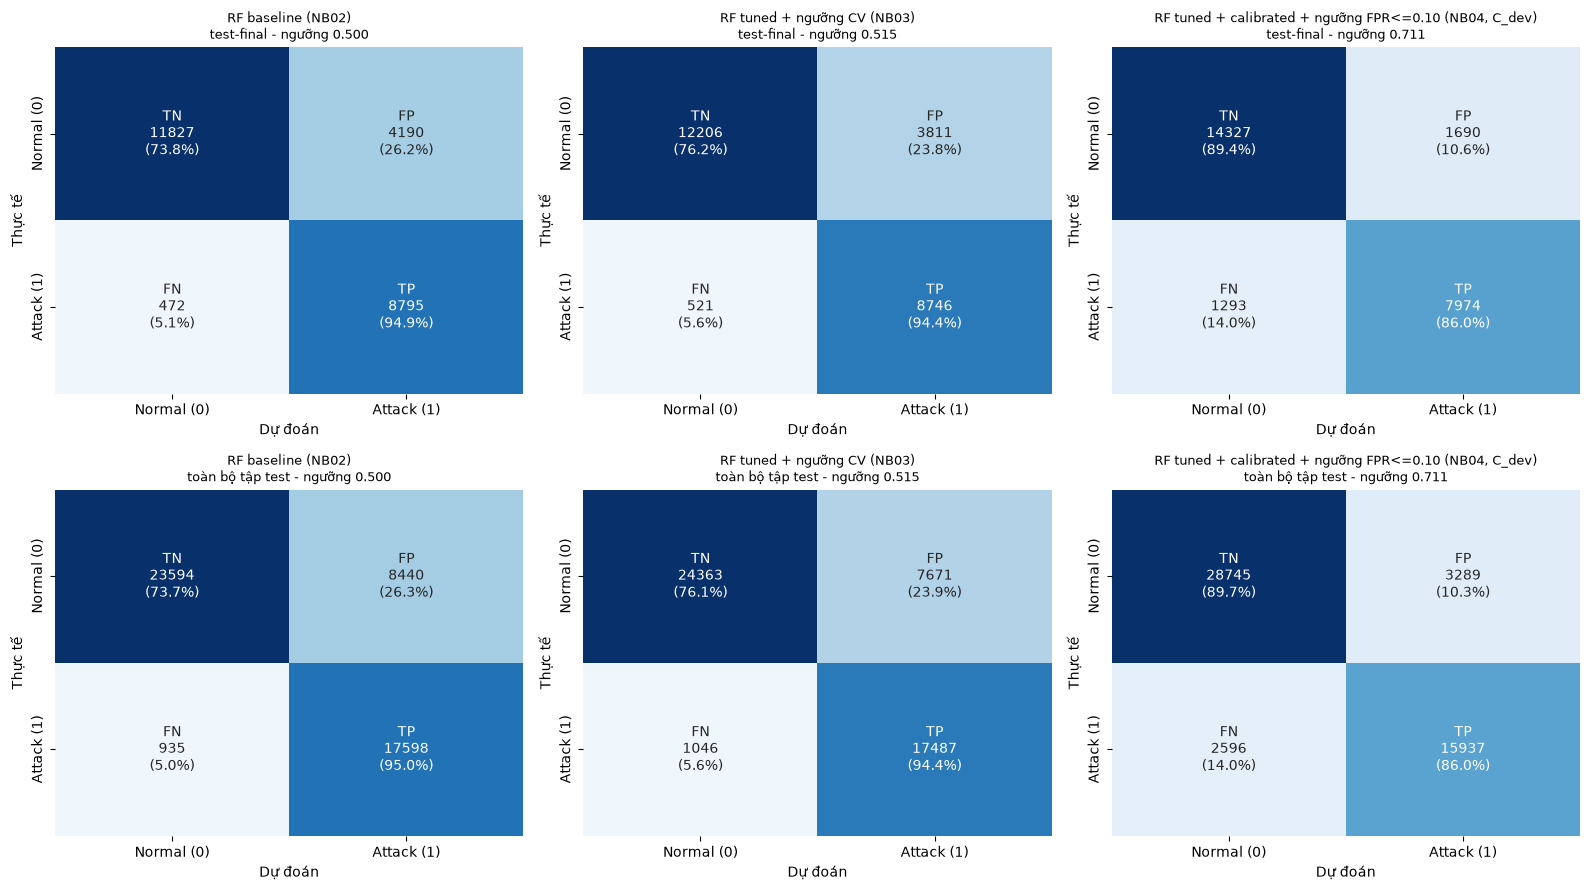

=== test-final (50% tập test, chung cho cả 3 model) ===
RF baseline (NB02): TN=11827.0  FP=4190.0  FN=472.0  TP=8795.0
RF tuned + ngưỡng CV (NB03): TN=12206.0  FP=3811.0  FN=521.0  TP=8746.0
RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04, C_dev): TN=14327.0  FP=1690.0  FN=1293.0  TP=7974.0

=== toàn bộ tập test (như notebook 02/03 báo cáo) ===
RF baseline (NB02): TN=23594.0  FP=8440.0  FN=935.0  TP=17598.0
RF tuned + ngưỡng CV (NB03): TN=24363.0  FP=7671.0  FN=1046.0  TP=17487.0
RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04, C_dev): TN=28745.0  FP=3289.0  FN=2596.0  TP=15937.0



In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, set_name in enumerate([EVAL_MAIN, EVAL_FULL]):
    for col, name in enumerate(models):
        r = all_results.loc[(set_name, name)]
        cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]], dtype=int)
        pct = cm / cm.sum(axis=1, keepdims=True)
        annot = [[f'TN\n{cm[0, 0]}\n({pct[0, 0]:.1%})', f'FP\n{cm[0, 1]}\n({pct[0, 1]:.1%})'],
                 [f'FN\n{cm[1, 0]}\n({pct[1, 0]:.1%})', f'TP\n{cm[1, 1]}\n({pct[1, 1]:.1%})']]
        ax = axes[row, col]
        sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=ax, vmin=0,
                    xticklabels=['Normal (0)', 'Attack (1)'], yticklabels=['Normal (0)', 'Attack (1)'])
        ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế')
        ax.set_title(f"{name}\n{set_name.split(' (')[0]} - ngưỡng {r['Ngưỡng']:.3f}", fontsize=9)
plt.tight_layout()
os.makedirs(reports_dir, exist_ok=True)
fig.savefig(os.path.join(reports_dir, 'confusion_matrices.png'), dpi=120, bbox_inches='tight')
plt.show()

# Bản text của ma trận nhầm lẫn (để đọc không cần hình)
for set_name in [EVAL_MAIN, EVAL_FULL]:
    print(f'=== {set_name} ===')
    for name in models:
        r = all_results.loc[(set_name, name)]
        print(f"{name}: TN={r['TN']}  FP={r['FP']}  FN={r['FN']}  TP={r['TP']}")
    print()

## 6. Các cấu hình phụ của notebook 04 trên `test-final`

Notebook 04 còn đánh giá hai bước trung gian (A = chưa calibrate @0.5, B = đã calibrate @0.5) và một
cấu hình so sánh định trước (C_val = ngưỡng chọn trên validation thay vì test-dev). Số liệu lấy từ
`models/random_forest_v3_metrics.json` của lần chạy gần nhất, trên cùng tập `test-final`.

In [9]:
extra = pd.DataFrame(m3['test_final']).T
display(extra[['accuracy', 'precision', 'recall', 'f1', 'TN', 'FP', 'FN', 'TP', 'fpr', 'threshold']]
        .astype(float).round(4))

,accuracy,precision,recall,f1,TN,FP,FN,TP,fpr,threshold
Lần 1 (đã lưu) @0.5,0.8156,0.6773,0.9491,0.7905,11827.0,4190.0,472.0,8795.0,0.2616,0.5000
Lần 2 (đã lưu) @0.515,0.8287,0.6965,0.9438,0.8015,12206.0,3811.0,521.0,8746.0,0.2379,0.5152
A: RF @0.5,0.8186,0.6813,0.9491,0.7932,11903.0,4114.0,472.0,8795.0,0.2569,0.5000
B: Calibrated @0.5,0.8289,0.6976,0.9413,0.8013,12235.0,3782.0,544.0,8723.0,0.2361,0.5000
C_val: Calibrated @0.464,0.8122,0.6715,0.9545,0.7884,11690.0,4327.0,422.0,8845.0,0.2702,0.4636
C_dev (CẤU HÌNH CHỌN): Calibrated @0.711,0.8820,0.8251,0.8605,0.8424,14327.0,1690.0,1293.0,7974.0,0.1055,0.7106


## 7. Lưu kết quả tổng hợp

In [10]:
out = all_results.reset_index()
out['Tập đánh giá'] = out['Tập đánh giá'].map({EVAL_MAIN: 'test-final', EVAL_FULL: 'full-test'})
out['Notebook'] = out['Model'].map({'RF baseline (NB02)': '02_Model_Training.ipynb',
                                    'RF tuned + ngưỡng CV (NB03)': '03_Model_Training_v2.ipynb',
                                    'RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04, C_dev)':
                                        '04_Precision_Improvement.ipynb'})
out['Quy tắc quyết định'] = 'Attack nếu P(Attack) >= Ngưỡng'
out['Ghi chú'] = np.where((out['Tập đánh giá'] == 'full-test') & out['Model'].str.contains('NB04'),
                          'LẠC QUAN: ngưỡng được chọn trên test-dev, là nửa của tập test này', '')
out.loc[out['Model'].str.contains('NB02'), 'Ghi chú'] = (
    'NB02 tự báo cáo bằng predict() (argmax, hoà về Normal); xem mục 4b')
cols = ['Model', 'Notebook', 'Tập đánh giá', 'Accuracy', 'Precision', 'Recall', 'F1',
        'TN', 'FP', 'FN', 'TP', 'FPR', 'Balanced acc', 'ROC-AUC', 'PR-AUC', 'Ngưỡng',
        'Quy tắc quyết định', 'Ghi chú']
out = out[cols]
for c in ['Accuracy', 'Precision', 'Recall', 'F1', 'FPR', 'Balanced acc', 'ROC-AUC', 'PR-AUC', 'Ngưỡng']:
    out[c] = out[c].astype(float).round(6)

csv_path = os.path.join(BASE, 'notebooks', 'model_comparison_results.csv')
out.to_csv(csv_path, index=False, encoding='utf-8-sig')
params_table.to_csv(os.path.join(BASE, 'notebooks', 'model_comparison_parameters.csv'), encoding='utf-8-sig')
display(out)
print('Đã lưu:', csv_path)
print('Đã lưu:', os.path.join(reports_dir, 'confusion_matrices.png'))

,Model,Notebook,Tập đánh giá,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,FPR,Balanced acc,ROC-AUC,PR-AUC,Ngưỡng,Quy tắc quyết định,Ghi chú
0,RF baseline (NB02),02_Model_Training.ipynb,test-final,0.815615,0.677320,0.949067,0.790491,11827.0,4190.0,472.0,8795.0,0.261597,0.843735,0.954842,0.926396,0.500000,Attack nếu P(Attack) >= Ngưỡng,"NB02 tự báo cáo bằng predict() (argmax, hoà về..."
1,RF tuned + ngưỡng CV (NB03),03_Model_Training_v2.ipynb,test-final,0.828666,0.696504,0.943779,0.801503,12206.0,3811.0,521.0,8746.0,0.237935,0.852922,0.960048,0.941954,0.515152,Attack nếu P(Attack) >= Ngưỡng,
2,RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04...,04_Precision_Improvement.ipynb,test-final,0.882020,0.825124,0.860473,0.842428,14327.0,1690.0,1293.0,7974.0,0.105513,0.877480,0.959549,0.941609,0.710631,Attack nếu P(Attack) >= Ngưỡng,
3,RF baseline (NB02),02_Model_Training.ipynb,full-test,0.814602,0.675858,0.949549,0.789661,23594.0,8440.0,935.0,17598.0,0.263470,0.843040,0.955440,0.928735,0.500000,Attack nếu P(Attack) >= Ngưỡng,"NB02 tự báo cáo bằng predict() (argmax, hoà về..."
4,RF tuned + ngưỡng CV (NB03),03_Model_Training_v2.ipynb,full-test,0.827615,0.695087,0.943560,0.800485,24363.0,7671.0,1046.0,17487.0,0.239464,0.852048,0.960299,0.942760,0.515152,Attack nếu P(Attack) >= Ngưỡng,
5,RF tuned + calibrated + ngưỡng FPR<=0.10 (NB04...,04_Precision_Improvement.ipynb,full-test,0.883620,0.828930,0.859926,0.844143,28745.0,3289.0,2596.0,15937.0,0.102672,0.878627,0.959887,0.942397,0.710631,Attack nếu P(Attack) >= Ngưỡng,"LẠC QUAN: ngưỡng được chọn trên test-dev, là n..."


Đã lưu: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project\notebooks\model_comparison_results.csv
Đã lưu: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project\reports\confusion_matrices.png
